In [18]:
# Librerie
from sktime.transformations.series.outlier_detection import HampelFilter
from sktime.transformations.series.func_transform import FunctionTransformer
# Per leggere i file
import gzip
import pickle

# Usual suspects
import matplotlib.pyplot as plt
import random
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# Decomposition for Denoiseing
from statsmodels.tsa.seasonal import seasonal_decompose

# PAA e SAX
# non è la libreria del prof, ma la sua è datata e serve un miracolo per farla funzionare
from tslearn.piecewise import PiecewiseAggregateApproximation as PAA
from tslearn.piecewise import SymbolicAggregateApproximation as SAX

## Caricamento Dati
---
Il dataset viene definito direttamente ts. Qui ho anche verificato quali colonne cambiano all'interno di una time series e quali restano invece costanti (tipo id)

In [15]:
# Dataset
with gzip.open("CMI_timeseries_dataset.pkl.gz", "rb") as f:
    ts = pickle.load(f)

In [16]:
# Verifica della costanza delle variabili all'interno di ogni time series, e creazione di colonne_fisse
colonne_da_verificare = ts[0].columns.tolist()


# per ora sono tutte "Costanti"
costanti = {col: True for col in colonne_da_verificare}

for df in ts:
    for col in colonne_da_verificare:
        if col in df.columns:
            # Se la variabile è già stata marcata come "non costante", saltiamo il controllo
            if not costanti[col]:
                continue

            # Se troviamo una time series con più di un valore unico, la variabile non è costante
            if df[col].nunique(dropna=False) > 1:
                costanti[col] = False

# Print finale molto gagliardo
for col, is_constant in costanti.items():
    if is_constant:
        print(f"{col}: COSTANTE")
    else:
        print(f"{col}: VARIABILE")

colonne_fisse = ['weekday', 'quarter',
                 'relative_date_PCIAT', 'id', 'sii_binary']

X: VARIABILE
Y: VARIABILE
Z: VARIABILE
enmo: VARIABILE
anglez: VARIABILE
non-wear_flag: VARIABILE
light: VARIABILE
battery_voltage: VARIABILE
weekday: COSTANTE
quarter: COSTANTE
relative_date_PCIAT: COSTANTE
id: COSTANTE
sii_binary: COSTANTE


## Grafici Esplorativi
---
Gli stessi grafici li ripropongo anche in una sessione successiva dedicata alla visualizzazione di ogni step della pulizia, per vedere come i dati cambiano nel tempo.
In un secondo momento possiamo sicuramente eliminare questa parte, per ora sta qui all'inizio.
Le time series sono estratte casualmente (per ora senza seed) dall'universo

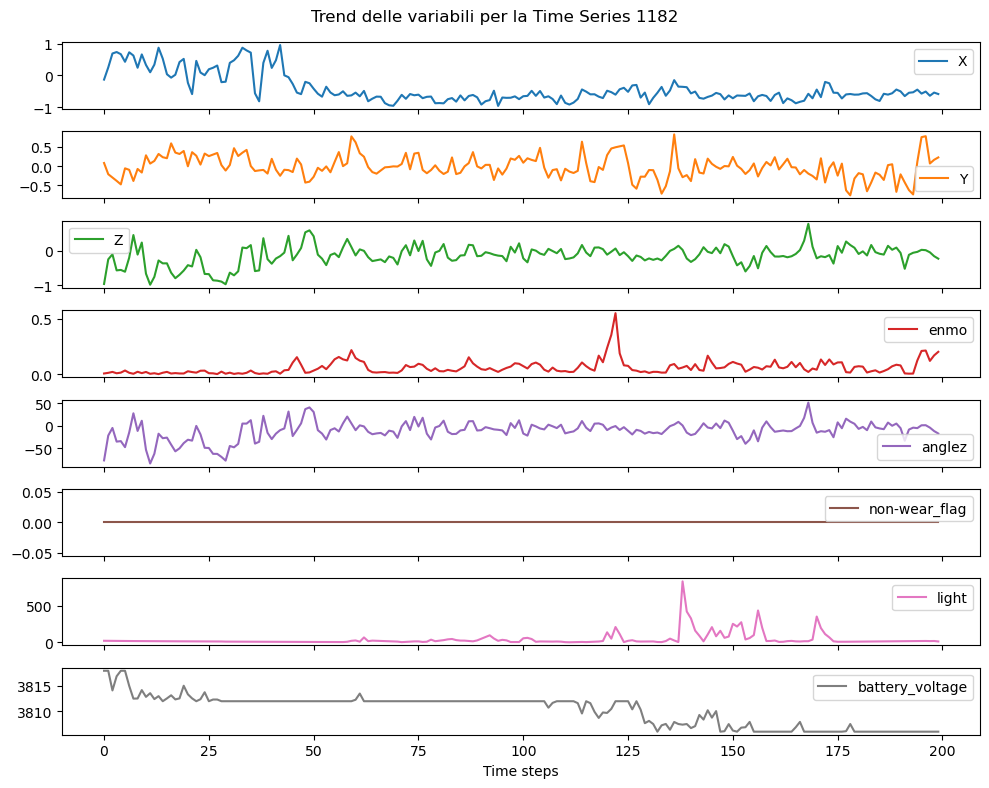

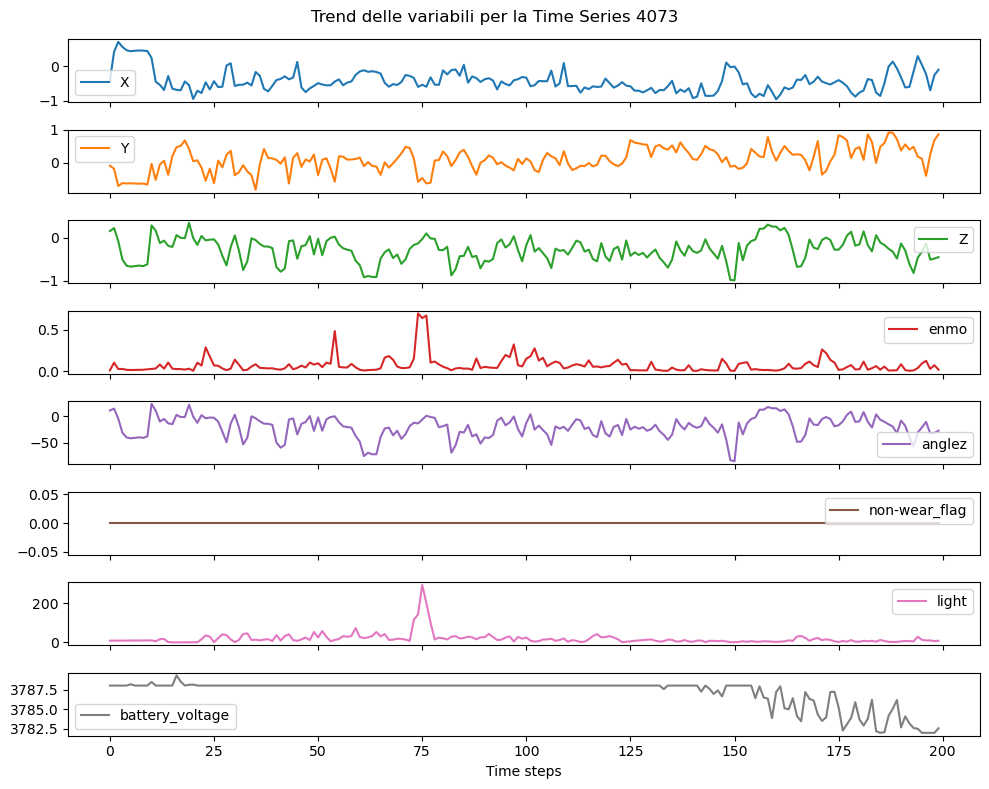

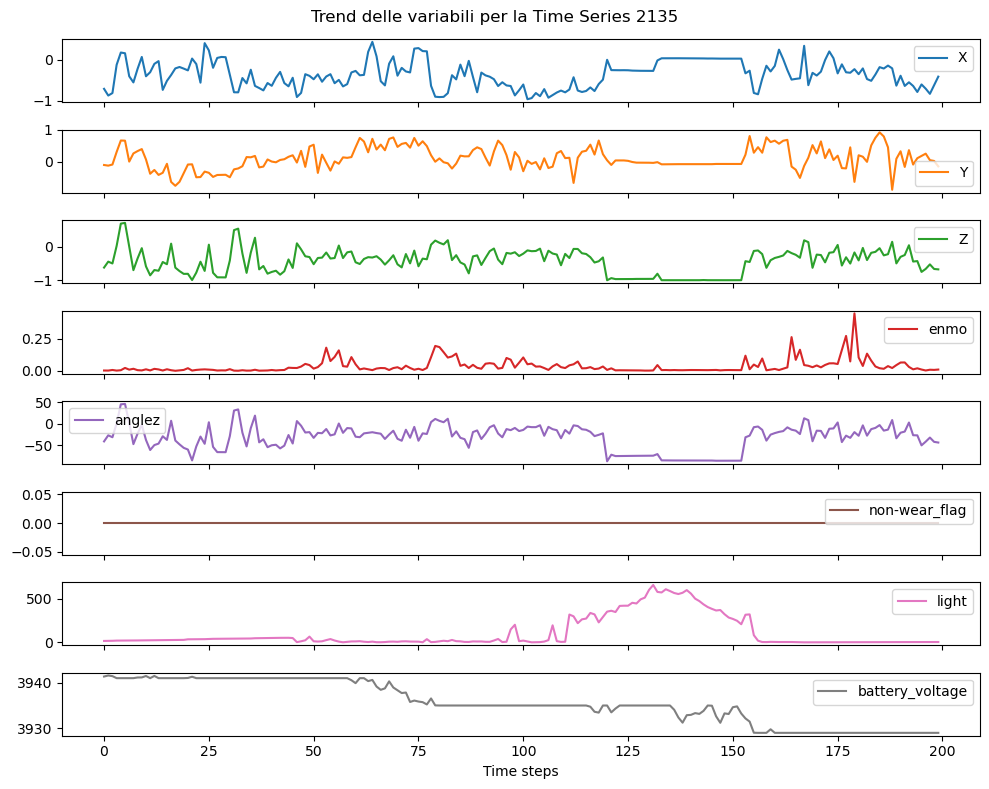

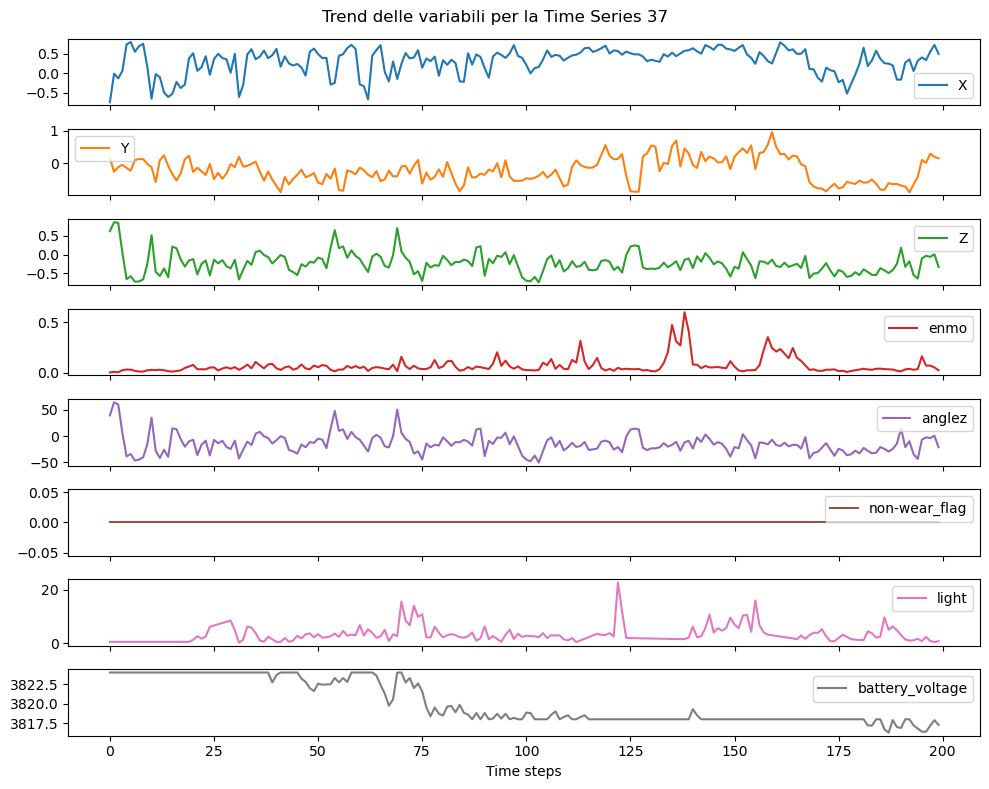

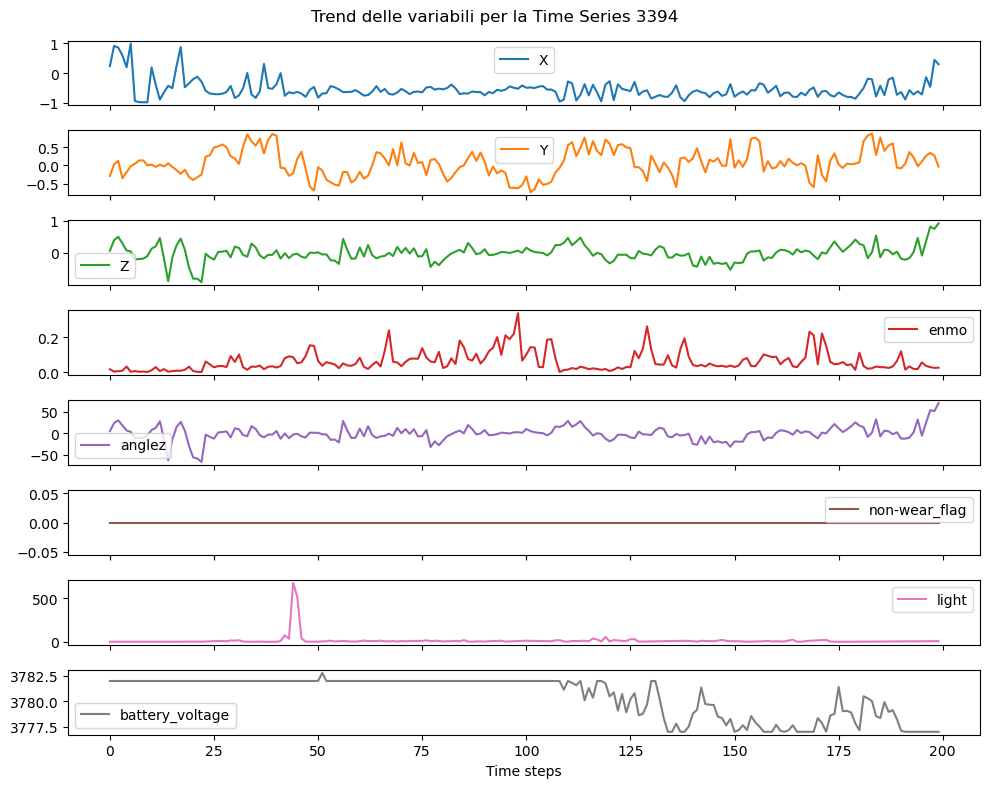

In [5]:
indice = random.sample(range(0, 4437), 5)

for i in indice:
    prova = ts[i]
    prova = prova.drop(colonne_fisse, axis=1)
    ax_array = prova.plot(
        kind='line',
        subplots=True,
        figsize=(10, 8),
        title=f"Trend delle variabili per la Time Series {i}",
        # Condivide l'asse X (i time steps 0-200) tra tutti i grafici
        sharex=True
    )

    # 5. Formattazione e visualizzazione
    plt.xlabel("Time steps")
    plt.tight_layout()  # Ottimizza gli spazi tra i grafici per evitare sovrapposizioni di testo
    plt.show()

## Missing Values
---
Ho controllato l'esistenza di missing values su tutto il dataset; sono assenti, meno roba da fare per noi :]

In [6]:
# Ricerca valori mancanti

# Calcola la somma dei NaN per ogni colonna in ciascuna time series.
# Il risultato è un nuovo DataFrame dove:
# - Le righe rappresentano le singole time series
# - Le colonne sono le variabili originali
# - I valori sono il numero di NaN presenti
missing_matrix = pd.DataFrame([df.isna().sum()
                              for df in ts])

# 1. Somma complessiva dei NaN per ogni variabile in tutto il dataset
totale_nan = missing_matrix.sum()

# 2. Conteggio di quante time series presentano almeno un NaN (> 0) per ogni variabile
ts_coinvolte = (missing_matrix > 0).sum()

# Visualizzazione dei risultati
totale_ts = len(ts)
print("--- Report Globale Missing Values Ottimizzato ---")

if totale_nan.sum() == 0:
    print("Il dataset è completo. Nessun missing value rilevato in alcuna variabile.")
else:
    for colonna in totale_nan.index:
        nan_count = totale_nan[colonna]

        # Filtra e stampa solo le variabili che hanno effettivamente valori mancanti
        if nan_count > 0:
            ts_count = ts_coinvolte[colonna]
            percentuale_ts = (ts_count / totale_ts) * 100

            print(f"Variabile: '{colonna}'")
            print(f"  - NaN totali: {nan_count}")
            print(
                f"  - Presenti in: {ts_count} time series ({percentuale_ts:.2f}% del dataset)\n")


# PS: Ho aggiunto degli NA a mano per testare il codice, e li ha trovati subito quindi funziona

--- Report Globale Missing Values Ottimizzato ---
Il dataset è completo. Nessun missing value rilevato in alcuna variabile.


## Denoising 
---
Per il Denoiseing ho utilizzato sia Moving Average che la Decomposition, va scelto quale tenere.
- Moving Average è migliore IMO: la Decomposition sucks in this case.
Molto semplicemente non conosciamo il periodo delle rilevazioni (200 sono minuti, secondi, decine di secondi?), quindi quel parametro è completamente arbitrario. 
Inoltre, non sono sicuro che vi sia una vera stagionalità nel dataset, poichè non è chiaro in che contesto stiamo monitorando i bambini (credo che sia un intero giorno di monitoraggio, ma non ce scritto)

In [7]:
# colonne per entrambi i metodi. Per ora sta fuori, quando decidiamo il metodo torna dentro
colonne_no_noise = colonne_fisse + ['non-wear_flag']

In [8]:
ts_denoised = []

for df in ts:
    df_pulito = df.copy()
    colonne_target = [
        col for col in df_pulito.columns if col not in colonne_no_noise]

    df_pulito[colonne_target] = df_pulito[colonne_target].rolling(
        window=5, min_periods=1).mean()

    ts_denoised.append(df_pulito)

In [9]:
periodo_stagionalita = 10  # questo parametro non so proprio come sceglierlo

ts_denoised_dc = []

for df in ts:
    df_pulito = df.copy()

    colonne_target = [
        col for col in df_pulito.columns if col not in colonne_no_noise]

    for col in colonne_target:
        decomposizione = seasonal_decompose(
            df_pulito[col],
            model='additive',
            period=periodo_stagionalita,
            extrapolate_trend='freq'
        )

        # Questa parte è un attimo diverso dalle slide. Nelle Slide, per fare il Denoise, si usa Y’ = Y - R; però, visto che sappiamo che
        # Y = T + S + R, allora si può scrivere Y’ = T + S
        df_pulito[col] = decomposizione.trend + decomposizione.seasonal

    ts_denoised_dc.append(df_pulito)

In [19]:
# here we lower the threshold to detect more outliers (default n_sigma is 3)
annotator = HampelFilter(window_length=12, n_sigma=3, return_bool=True)

labels = annotator.fit_transform(ts_denoised).ravel()

plt.plot(ts.ravel())
plt.scatter(np.arange(len(labels)), ts, alpha=labels, color="red", marker="x")
plt.show()

KeyboardInterrupt: 

## Normalizzazione
---
Per la normalizzazione ho deciso di usare entrambi gli approcci: Standard e MinMax.
- Per le variabili di movimento ho usato standard instance-wise, in modo tale da scalare tutte le variabili mantenendo la FORMA (quindi se bambini hanno fatto movimenti simili ma con intensità diverse, l'informazione si mantiene).
- Per le variabili di luce e batteria ho usato minmax dataset-wise, cos' da portare tutto nella solita scala, mantenendo le differenze di intensità dei valori. Se si fa instancewise e il bambino è rimasto tutto il giorno chiuso in casa, ci sta che 0=buio, 1 = leggermente meno buio, e la cosa non trasla per un bambino che magari è stato in casa e poi è uscito. Facendo datasetwise, 0 = buio, 1 = luminoso a prescindere da cosa ha fatto lo specifico bambino

In [10]:
variabili_std = ['X', 'Y', 'Z', 'enmo', 'anglez']
variabili_minmax = ['light', 'battery_voltage']
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Calcolo dei min e max. Si concatenano tutti i valori delle 2 variabili (tra tutte le ts) e si trovano i minimi e massimi globali
dati_minmax_globali = pd.concat(
    [df[variabili_minmax] for df in ts_denoised], ignore_index=True)
minmax_scaler.fit(dati_minmax_globali)

ts_normalized = []

for df in ts_denoised:
    df_norm = df.copy()

    df_norm[variabili_std] = std_scaler.fit_transform(df_norm[variabili_std])

    df_norm[variabili_minmax] = minmax_scaler.transform(
        df_norm[variabili_minmax])

    ts_normalized.append(df_norm)

## Approssimazione
---
Onestamente non so ancora se serve. Lo ho fatto ma magari non si usa nelle analisi. L'unica opzione viabile è PAA:
- Nella consegna abbiamo PAA o SAX (time-dependent approximations)
- Fourier non è solo scartato nella consegna del preprocessing, ma ho visto che nella classification bisogna fare K-nn con DTW, quindi ci servono le dipendenze temporali
- SAX, come si evince dal nome, sucks. Non vedo perchè mai vorremmo approssimare il dataset con delle lettere quando possiamo farlo con dei numeri 

In [11]:
# PAA

paa = PAA(n_segments=20)
ts_paa_array = paa.fit_transform(ts_normalized)

ts_transformed_paa = []

nomi_colonne = ts_normalized[0].columns

for matrice_ts in ts_paa_array:
    df_approssimato = pd.DataFrame(matrice_ts, columns=nomi_colonne)
    ts_transformed_paa.append(df_approssimato)

In [12]:
# SAX
sax = SAX(n_segments=20, alphabet_size_avg=5)

# Trasformazione: l'output è un array numpy 3D: (n_ts, n_segments, n_features)
ts_sax_array = sax.fit_transform(ts_normalized)

# Riconversione in lista di DataFrame per preservare la struttura e la leggibilità
ts_transformed_sax = []
nomi_colonne = ts_normalized[0].columns

for matrice_ts in ts_sax_array:
    df_sax = pd.DataFrame(matrice_ts, columns=nomi_colonne)
    ts_transformed_sax.append(df_sax)

## Confronto Grafici
---

Grafici Iniziali


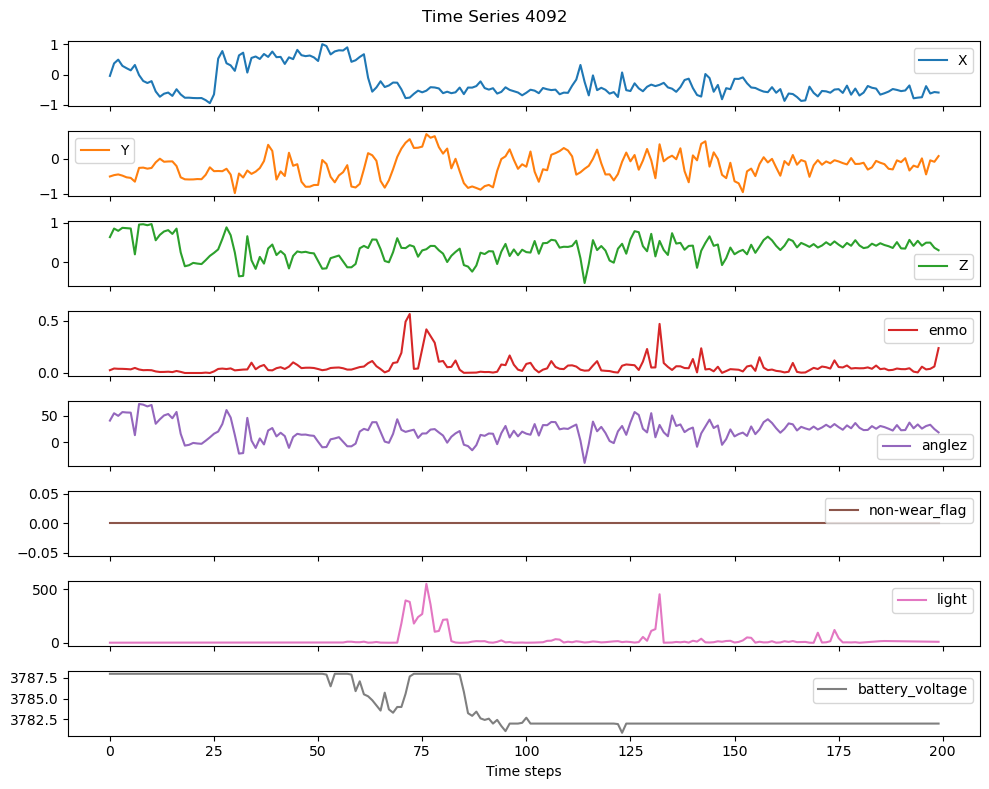

Grafici Denoised


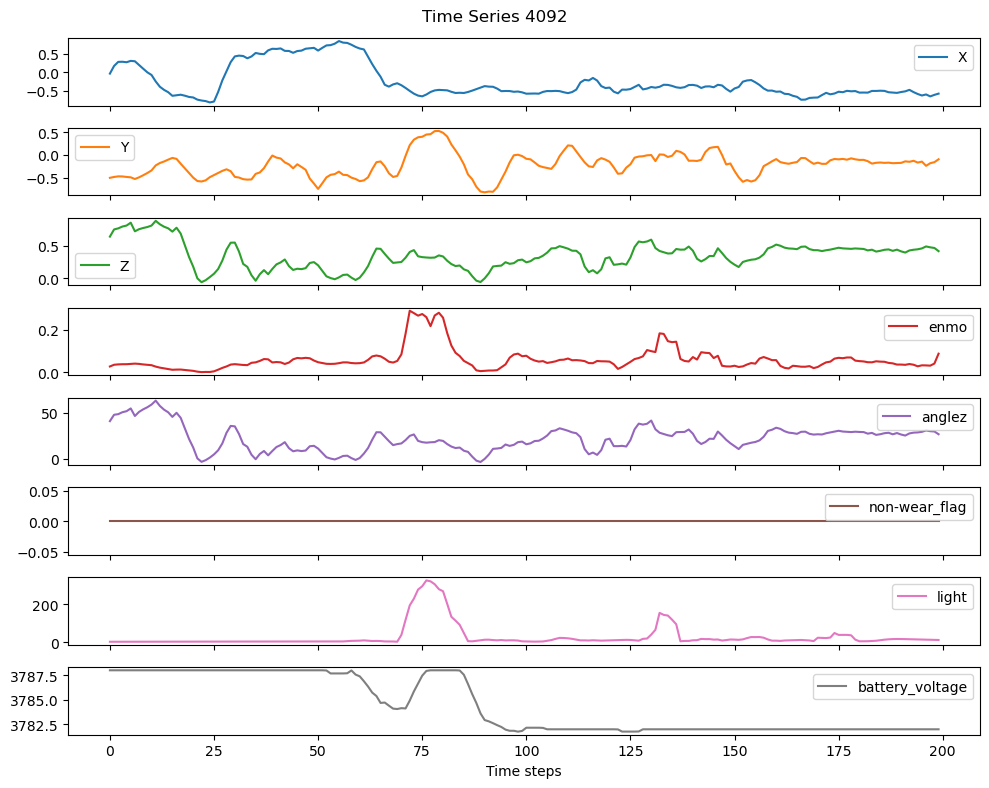

Grafici Normalizzati


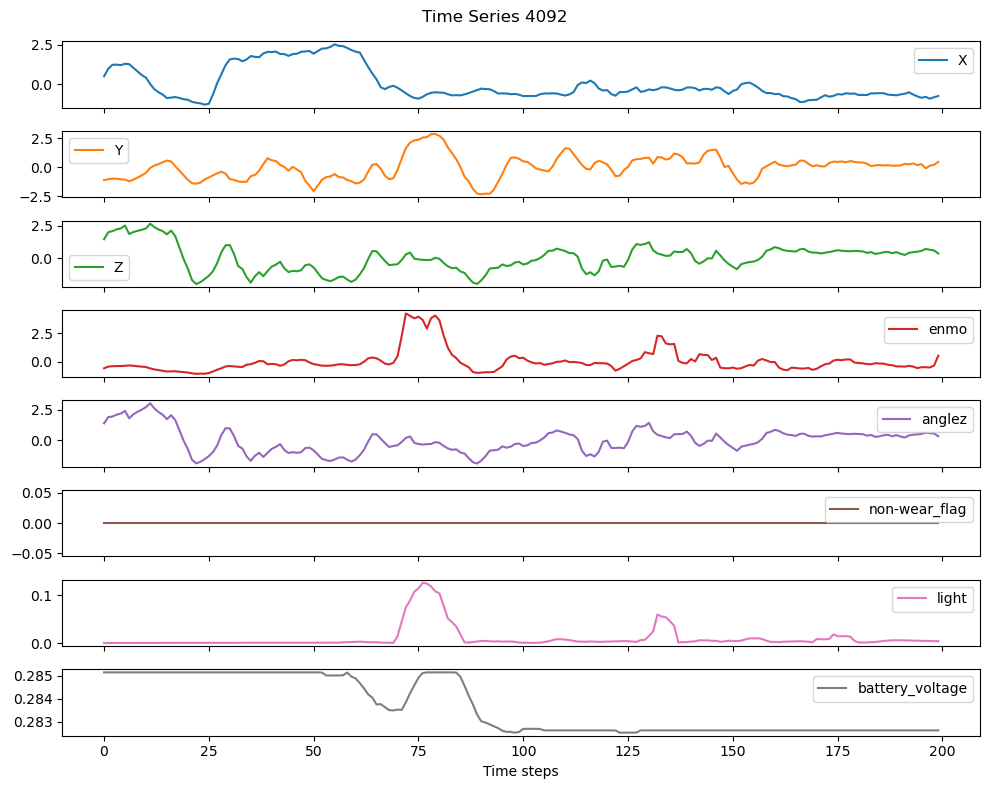

In [13]:
indice = random.sample(range(0, 4437), 1)

print("Grafici Iniziali")
for i in indice:
    prova = ts[i]
    prova = prova.drop(colonne_fisse, axis=1)
    ax_array = prova.plot(
        kind='line',
        subplots=True,
        figsize=(10, 8),
        title=f"Time Series {i}",
        sharex=True  # stessa asse x
    )

    plt.xlabel("Time steps")
    plt.tight_layout()
    plt.show()

print("Grafici Denoised")
for i in indice:
    prova = ts_denoised[i]
    prova = prova.drop(colonne_fisse, axis=1)
    ax_array = prova.plot(
        kind='line',
        subplots=True,
        figsize=(10, 8),
        title=f"Time Series {i}",
        sharex=True
    )

    plt.xlabel("Time steps")
    plt.tight_layout()
    plt.show()

print("Grafici Normalizzati")
for i in indice:
    prova = ts_normalized[i]
    prova = prova.drop(colonne_fisse, axis=1)
    ax_array = prova.plot(
        kind='line',
        subplots=True,
        figsize=(10, 8),
        title=f"Time Series {i}",
        sharex=True
    )

    plt.xlabel("Time steps")
    plt.tight_layout()
    plt.show()